# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

DIR_PROC = Path("..") / "data" / "processed"


## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [3]:
df = pd.read_csv(DIR_PROC / "dataset.csv")

print(f"Dimensões do dataset: {df.shape}")
display(df.head())
print(df.info())

Dimensões do dataset: (168, 15)


,data_hora,altura_m,coeficiente_num,coeficiente_desc,direcao_onda,altura_onda,hora_x,direcao_vento,velocidade_vento,hora_y,ano,mes,dia,hora,dia_da_semana
0,2026-10-11 00:00:00,1.6,49,baixo,ESE,1.0,0,ESE,22,0,2026,10,11,0,Sunday
1,2026-10-11 01:00:00,1.8,49,baixo,ESE,1.0,1,SE,21,1,2026,10,11,1,Sunday
2,2026-10-11 02:00:00,2.0,56,médio,ESE,1.0,2,ESE,19,2,2026,10,11,2,Sunday
3,2026-10-11 03:00:00,2.0,56,médio,ESE,1.0,3,ESE,18,3,2026,10,11,3,Sunday
4,2026-10-11 04:00:00,2.0,56,médio,ESE,1.0,4,ESE,19,4,2026,10,11,4,Sunday


<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   data_hora         168 non-null    str    
 1   altura_m          168 non-null    float64
 2   coeficiente_num   168 non-null    int64  
 3   coeficiente_desc  168 non-null    str    
 4   direcao_onda      168 non-null    str    
 5   altura_onda       168 non-null    float64
 6   hora_x            168 non-null    int64  
 7   direcao_vento     168 non-null    str    
 8   velocidade_vento  168 non-null    int64  
 9   hora_y            168 non-null    int64  
 10  ano               168 non-null    int64  
 11  mes               168 non-null    int64  
 12  dia               168 non-null    int64  
 13  hora              168 non-null    int64  
 14  dia_da_semana     168 non-null    str    
dtypes: float64(2), int64(8), str(5)
memory usage: 19.8 KB
None


## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

### Regras

- **Variáveis utilizadas na regra:** A regra considera a altura da onda (`altura_onda`) e a velocidade do vento (`velocidade_vento`).
  - **Ruim (0):** Mar muito baixo/flat (< 0.6m), mar excessivamente revolto (> 2.2m) ou ventos fortes demais (> 25 km/h) que estragam a formação das ondas.
  - **Ótimo (2):** Janela ideal com ondas limpas entre 1.0m e 1.8m e ventos controlados (<= 20 km/h).
  - **Bom (1):** Condições intermediárias aceitáveis.


In [14]:
def classifica_condicao(row):
    hora = row['hora']
    altura = row['altura_onda']
    vento = row['velocidade_vento']

    if hora < 5 or hora >= 18:
        return 0
    
    elif altura < 0.6 or altura > 2.2 or vento > 25:
        return 0  
    
    elif 1.0 <= altura <= 1.8 and vento <= 20:
        return 2  
    
    else:
        return 1  


df['condicao'] = df.apply(classifica_condicao, axis=1)

In [16]:
print("Distribuição das classes (%):")
print((df['condicao'].value_counts(normalize=True).sort_index() * 100).round(1).astype(str) + '%')

Distribuição das classes (%):
condicao
0    49.4%
1    34.5%
2    16.1%
Name: proportion, dtype: str


## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

In [17]:
y = df['condicao']

features_base = df[['altura_m', 'coeficiente_num', 'altura_onda', 'velocidade_vento', 'hora']]
features_cat = pd.get_dummies(df[['direcao_onda', 'direcao_vento', 'coeficiente_desc']], drop_first=True)

X = pd.concat([features_base, features_cat], axis=1)

In [18]:
print(f"Shape de X (features): {X.shape}")
print(f"Shape de y (alvo): {y.shape}")
print("\nColunas de X:")
print(X.columns.tolist())

Shape de X (features): (168, 11)
Shape de y (alvo): (168,)

Colunas de X:
['altura_m', 'coeficiente_num', 'altura_onda', 'velocidade_vento', 'hora', 'direcao_onda_ESE', 'direcao_vento_ENE', 'direcao_vento_ESE', 'direcao_vento_SE', 'coeficiente_desc_baixo', 'coeficiente_desc_médio']


## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

In [19]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print(f"Tamanho de X_train: {X_train.shape[0]} linhas")
print(f"Tamanho de X_test:  {X_test.shape[0]} linhas\n")

print("Distribuição das classes no Treino (%):")
print((y_train.value_counts(normalize=True) * 100).round(1).astype(str) + '%')

print("\nDistribuição das classes no Teste (%):")
print((y_test.value_counts(normalize=True) * 100).round(1).astype(str) + '%')

Tamanho de X_train: 134 linhas
Tamanho de X_test:  34 linhas

Distribuição das classes no Treino (%):
condicao
0    49.3%
1    35.8%
2    14.9%
Name: proportion, dtype: str

Distribuição das classes no Teste (%):
condicao
0    50.0%
1    29.4%
2    20.6%
Name: proportion, dtype: str


## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [20]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [21]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

In [23]:
y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

acc_dt = accuracy_score(y_test, y_pred_dt)
acc_rf = accuracy_score(y_test, y_pred_rf)

In [24]:
print(f"Acurácia da Árvore de Decisão: {acc_dt * 100:.1f}%")
print(f"Acurácia da Random Forest:     {acc_rf * 100:.1f}%\n")

print("--- Relatório de Classificação (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

print("--- Matriz de Confusão (Random Forest) ---")
print(confusion_matrix(y_test, y_pred_rf))

Acurácia da Árvore de Decisão: 100.0%
Acurácia da Random Forest:     100.0%

--- Relatório de Classificação (Random Forest) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00         7

    accuracy                           1.00        34
   macro avg       1.00      1.00      1.00        34
weighted avg       1.00      1.00      1.00        34

--- Matriz de Confusão (Random Forest) ---
[[17  0  0]
 [ 0 10  0]
 [ 0  0  7]]


## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

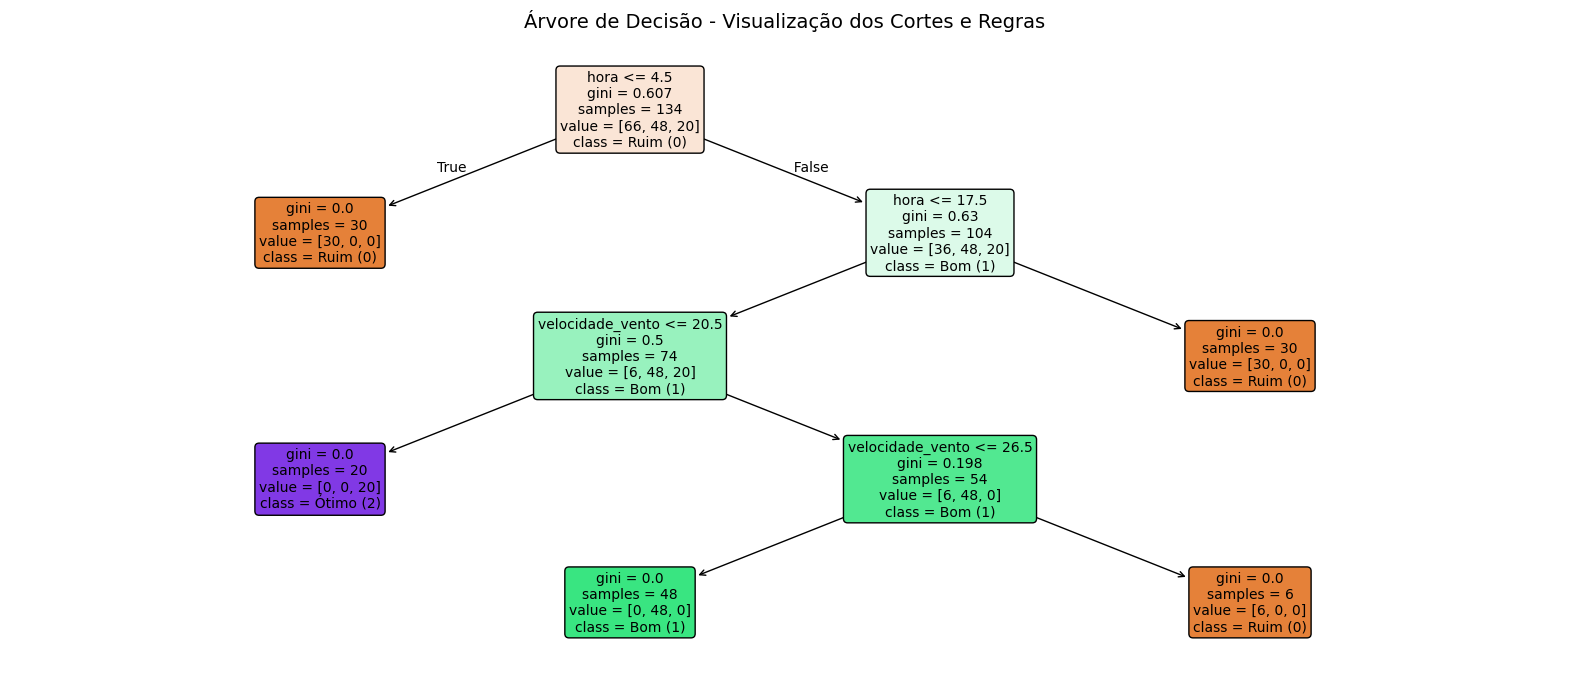

In [30]:
plt.figure(figsize=(20, 8))
plot_tree(
    dt_model, 
    feature_names=X.columns, 
    class_names=['Ruim (0)', 'Bom (1)', 'Ótimo (2)'], 
    filled=True, 
    rounded=True,
    fontsize=10 
)
plt.title("Árvore de Decisão - Visualização dos Cortes e Regras", fontsize=14, pad=15)
plt.show()

In [26]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- Importância das Features (Random Forest) ---")
print(importances.round(4))

--- Importância das Features (Random Forest) ---
hora                      0.4332
velocidade_vento          0.2664
altura_m                  0.1164
coeficiente_num           0.0653
altura_onda               0.0617
direcao_vento_ESE         0.0176
direcao_vento_ENE         0.0146
direcao_onda_ESE          0.0117
coeficiente_desc_médio    0.0081
direcao_vento_SE          0.0030
coeficiente_desc_baixo    0.0019
dtype: float64


## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.